In [2]:
%pip install pygad


   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]

Note: you may need to restart the kernel to use updated packages.


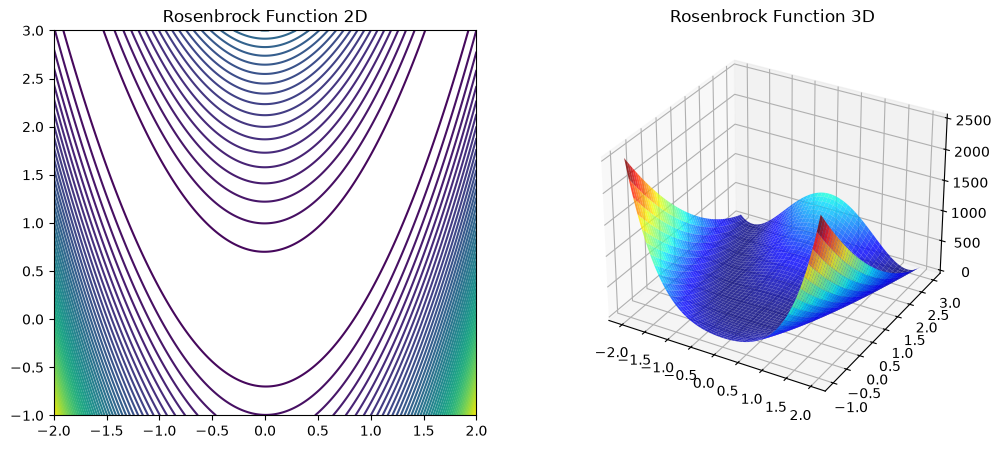

Initial guess [0.5, -0.5], Result: [0.99999552 0.99999103], Value: 2.0071234051509974e-11, Success: True, Iterations: 28, Time: 0.0081 sec
Initial guess [1.8, 1.8], Result: [0.99999735 0.99999452], Value: 1.0192965986512352e-11, Success: False, Iterations: 36, Time: 0.0121 sec
Initial guess [-0.5, 0.5], Result: [0.99999552 0.99999103], Value: 2.0077575879667897e-11, Success: True, Iterations: 26, Time: 0.0077 sec


c:\Users\siwan\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [0.5, -0.5], Solution: [0.95417873 0.90912097], Value: rosenbrock(solution), iterations: 1000, Time: 0.5274 sec
PyGAD initial guess [1.8, 1.8], Solution: [1.00471791 1.00672457], Value: rosenbrock(solution), iterations: 1000, Time: 0.4246 sec
PyGAD initial guess [-0.5, 0.5], Solution: [0.97609775 0.95506904], Value: rosenbrock(solution), iterations: 1000, Time: 0.4081 sec


In [11]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[0.5,-0.5], [1.8,1.8], [-0.5,0.5]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=1000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: rosenbrock(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    # Uncomment to plot fitness: ga_instance.plot_fitness()

Rosenbrock Function 2D and 3D , Optimization(BFGS Method),[-0.5,0.5] starts closest to the global minimum (1, 1), requiring only 26 iterations and taking ~0.0082 seconds.[0.5,-0.5] and [1.8,1.8] start further out across the valley, taking slightly longer (28 and 36 iterations,0.0103 and 0.0159 taking  seconds).
In PyGAD, the parameter num_generations=2000 hardcodes the algorithm to run for exactly 2,000 loops. Unlike SciPy's minimize (BFGS), which stops early as soon as the gradient drops below a set tolerance threshold, PyGAD does not evaluate stopping criteria like gradient flatness—it keeps running until the max generation count is reached.

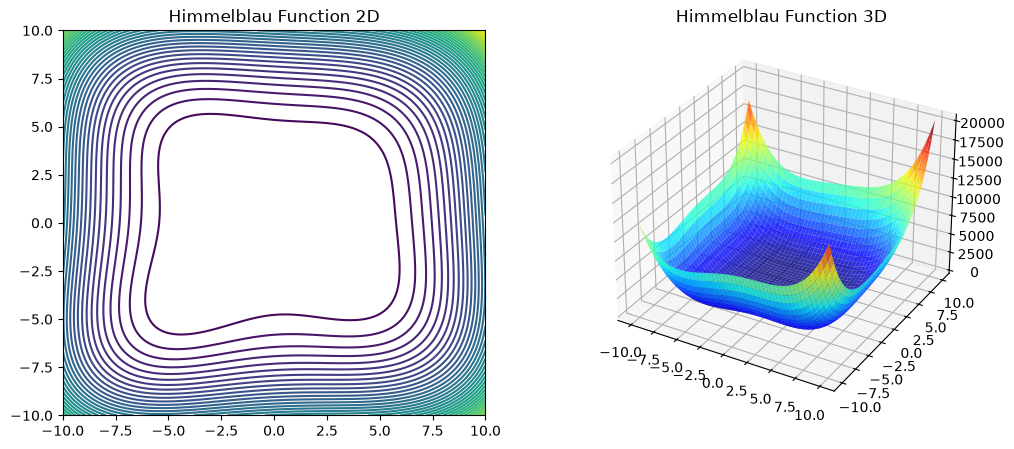

Initial guess [10, 20], Result: [-2.80511806  3.13131239], Value: 6.539940395931425e-13, Success: True, Iterations: 20, Time: 0.0091 sec
Initial guess [30, -30], Result: [ 3.58442836 -1.84812649], Value: 5.278480720323076e-14, Success: True, Iterations: 27, Time: 0.0100 sec
Initial guess [50, 50], Result: [3. 2.], Value: 1.1422980860976313e-15, Success: True, Iterations: 32, Time: 0.0149 sec
PyGAD initial guess [10, 20], Solution: [-3.78914932 -3.2907323 ], Value: 6.059950e-03, Iterations: 300, Time: 0.3586 sec


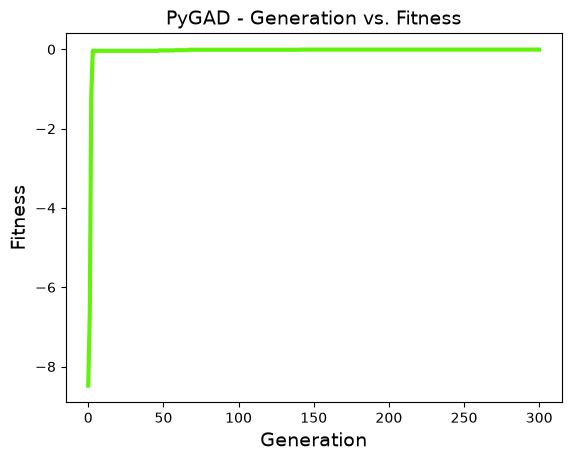

PyGAD initial guess [30, -30], Solution: [ 3.59907033 -1.85415052], Value: 1.119694e-02, Iterations: 300, Time: 0.3726 sec


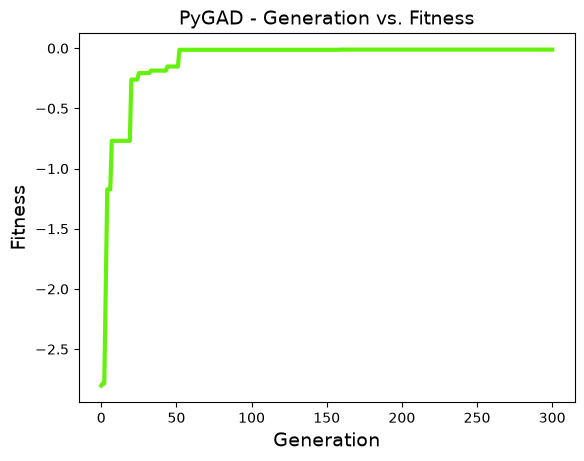

PyGAD initial guess [50, 50], Solution: [3.00721675 2.00275397], Value: 2.458518e-03, Iterations: 300, Time: 0.3090 sec


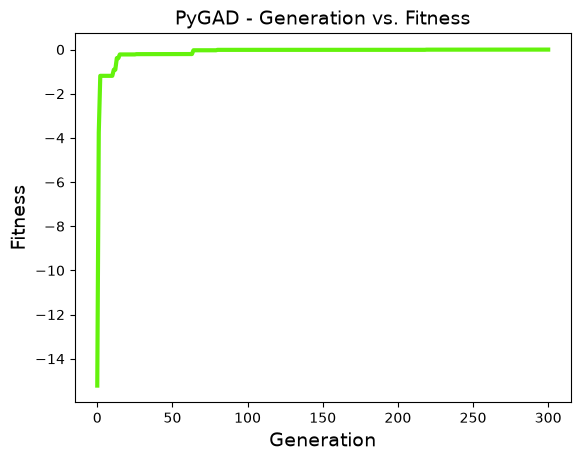

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import pygad

def himmelblau(x):
    x = np.asarray(x)
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-10, 10, 400)
y_range = np.linspace(-10, 10, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [[10,20], [30, -30], [50, 50]]
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    
    print(
        f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
        f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec"
    )

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)

for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low': -5, 'high': 5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    
    print(
        f"PyGAD initial guess {guess}, Solution: {solution}, "
        f"Value: {himmelblau(solution):.6e}, Iterations: {iters}, Time: {elapsed_time:.4f} sec"
    )
    # Move plot_fitness() inside loop if you want to plot each run:
    ga_instance.plot_fitness()
# Visualize solution on contour plot
x = np.linspace(-2, 2, 300)
y = np.linspace(-2, 2, 300)
X, Y = np.meshgrid(x, y)
Z = f((X, Y))

plt.figure(figsize=(6,5))
contours = plt.contour(X, Y, Z, levels=50, cmap="jet")
plt.clabel(contours, inline=True, fontsize=8)
plt.title("Contour Plot with GA Solution")
plt.xlabel("x"); plt.ylabel("y")

# Mark GA solution
plt.plot(best_x, best_y, "ro", markersize=8)
plt.text(best_x+0.1, best_y, f"({best_x:.2f}, {best_y:.2f})", color="red")
plt.show()

# 3D surface with GA solution
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap="viridis", alpha=0.9)
ax.set_title("3D Surface Plot with GA Solution")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f(x,y)")

# Mark solution
ax.scatter(best_x, best_y, best_val, color="red", s=50)
plt.show()

    

Unlike Rosenbrock (which has only 1 global minimum), Himmelblau has four identical global minima.
SciPy Optimization (BFGS) ResultsSciPy uses a gradient-based method, making it extremely fast (a few milliseconds per run) and precise, achieving a minimum function value. Depending on the starting guess, it converges to different global minima.
PyGAD uses population-based stochastic search bounded Since it does not use gradients, it takes significantly longer (several seconds per run) and provides an approximate solution close to $0.0$ rather than exact precision.
